# Pandas: Pivot Tables

In [ ]:
!pip install datasets

In [ ]:
# importing Libraries
import pandas as pd 
from datasets import load_dataset
import matplotlib.pyplot as plt 

# Loading Data
dataset = load_dataset('lukebarousse/data_jobs')
df=dataset['train'].to_pandas()

# Data Cleaning
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])

## Counts of Job_title


### pandas.DataFrame.pivot_table
#### DataFrame.pivot_table(values=None, index=None, columns=None, aggfunc='mean', fill_value=None, margins=False, dropna=True, margins_name='All', observed=True, sort=True, **kwargs)

In [ ]:
df.pivot_table(values='salary_year_avg', index= 'job_country', columns ='job_title_short', aggfunc='median')

job_title_short,Business Analyst,Cloud Engineer,Data Analyst,Data Engineer,Data Scientist,Machine Learning Engineer,Senior Data Analyst,Senior Data Engineer,Senior Data Scientist,Software Engineer
job_country,,,,,,,,,,
Albania,NaN,NaN,49950.00,NaN,69981.25,NaN,NaN,NaN,157500.0,NaN
Algeria,NaN,NaN,44100.00,45000.0,NaN,NaN,NaN,NaN,NaN,NaN
Argentina,71100.0,197500.0,92771.75,96773.0,71000.00,101029.0,NaN,147500.0,NaN,174500.0
Armenia,NaN,NaN,100500.00,48750.0,NaN,87021.0,NaN,NaN,NaN,NaN
Australia,70000.0,110000.0,109500.00,106712.5,139216.00,101029.0,50640.0,147500.0,157500.0,118350.0
...,...,...,...,...,...,...,...,...,...,...
Uruguay,NaN,NaN,100500.00,NaN,NaN,50000.0,NaN,NaN,57500.0,NaN
Uzbekistan,NaN,NaN,NaN,NaN,30750.00,NaN,NaN,NaN,NaN,NaN
Vietnam,79200.0,NaN,75550.00,96773.0,70000.00,57600.0,105837.5,147500.0,79200.0,53600.0


In [ ]:
df.groupby('job_title_short')['salary_year_avg'].median()

job_title_short
Business Analyst              85000.0
Cloud Engineer                90000.0
Data Analyst                  90000.0
Data Engineer                125000.0
Data Scientist               127500.0
Machine Learning Engineer    106415.0
Senior Data Analyst          111175.0
Senior Data Engineer         147500.0
Senior Data Scientist        155500.0
Software Engineer             99150.0
Name: salary_year_avg, dtype: float64

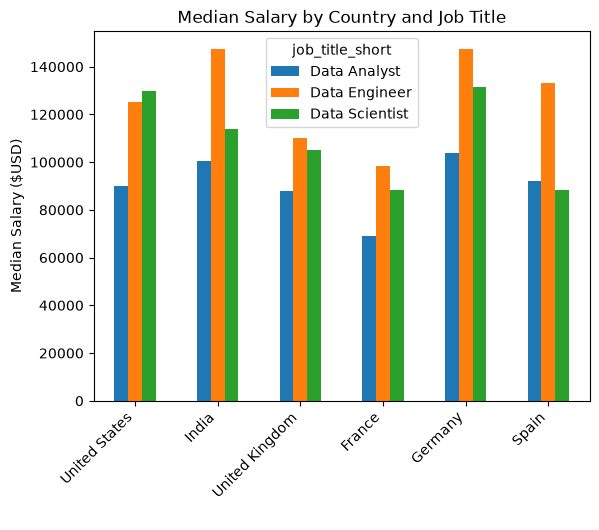

In [ ]:
top_countries = df['job_country'].value_counts().head(6).index
top_countries

df_job_country_salary = df.pivot_table(
    values='salary_year_avg', 
    index= 'job_country', 
    columns ='job_title_short', 
    aggfunc='median'
)

df_job_country_salary = df_job_country_salary.loc[top_countries]

job_titles = ['Data Analyst', 'Data Engineer', 'Data Scientist']
df_job_country_salary = df_job_country_salary[job_titles]
df_job_country_salary.plot(kind='bar')
plt.ylabel('Median Salary ($USD)')
plt.xlabel(' ')
plt.title('Median Salary by Country and Job Title')
plt.xticks(rotation=45, ha='right')
plt.show()

# Count Job Posting by Title and Country

In [ ]:
pivot_table = df.pivot_table(index= ['job_title_short', 'job_country'], aggfunc='size' )
pivot_table.head(10)

job_title_short   job_country
Business Analyst  Afghanistan      4
                  Albania         11
                  Algeria         21
                  Angola           1
                  Argentina      453
                  Armenia         29
                  Australia      928
                  Austria        738
                  Azerbaijan      16
                  Bahamas          5
dtype: int64

### Salary Stats by Job Title

In [ ]:
job_pivot_table = df.pivot_table(values='salary_year_avg', index='company_name', aggfunc=['min', 'max', 'mean'])
job_pivot_table.head(10)

,min,max,mean
,salary_year_avg,salary_year_avg,salary_year_avg
company_name,,,
#twiceasnice Recruiting,61000.000000,120000.000000,77750.000000
/dev/color,125000.000000,125000.000000,125000.000000
0nward Select,92500.000000,92500.000000,92500.000000
1 Point System,137290.484375,137290.484375,137290.484375
1 Point System LLC.,170000.000000,170000.000000,170000.000000
"1-800-FLOWERS.COM, INC.",190000.000000,190000.000000,190000.000000
100Insure,97500.000000,97500.000000,97500.000000
10x Genomics,155000.000000,155000.000000,155000.000000


### Sum Salary by Title and country

In [ ]:
pivot_table = df.pivot_table(values='salary_year_avg', index= ['company_name', 'job_country'], aggfunc='median')
filtered_pivot_table = pivot_table[pivot_table['salary_year_avg'] > 200_000]
filtered_pivot_table.head(10)